# NYC Airbnb Listings: Data Cleaning & Preprocessing

**DSA1101**

An end-to-end, reproducible cleaning pipeline for the 2019 *New York City Airbnb Open Data* (48,895 listings × 16 columns), using Python (pandas, NumPy, matplotlib). Every cleaning decision is logged, and the notebook ends with a raw-vs-cleaned comparison.

**Dataset:** [New York City Airbnb Open Data on Kaggle](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data). The raw CSV is not included here; check the license on the Kaggle page before redistributing it.

### Issues found and how they were handled

| Issue | What the data showed | Treatment |
|---|---|---|
| Missing review fields | `reviews_per_month` and `last_review` missing for 10,052 listings (20.56%), exactly the listings with 0 reviews | `reviews_per_month` → 0; `last_review` left empty; `has_reviews` flag added |
| Missing names | 16 listing names, 21 host names | Labelled `Unknown` |
| Messy text | 238 names with leading/trailing spaces, 1,387 with double spaces; 41 host names with double spaces | Trimmed and collapsed |
| Wrong data type | `last_review` stored as text | Converted to datetime |
| Duplicates | None (exact, repeated `id`, near-duplicate) | Checks kept; 0 rows dropped |
| Invalid prices | 11 listings priced at $0 | Removed |
| Extreme prices | Max $10,000; 239 listings above $1,000 | Capped at the 99th percentile ($799); `log_price` added |
| Extreme minimum nights | Max 1,250; 14 listings above 365 | Capped at 365 |
| Categorical variables | `room_type` (3), borough (5), `neighbourhood` (221) | One-hot encoding; frequency encoding for neighbourhood |

### Running this notebook

1. Download `AB_NYC_2019.csv` from the Kaggle link above.
2. **Local / GitHub clone:** put it in a `data/` folder next to the `notebooks/` folder (or next to this notebook), then run `pip install pandas numpy matplotlib jupyter` and open the notebook.
3. **Colab:** upload the CSV to the Colab file panel. **Kaggle:** add the dataset to the notebook.

The loader in Section 2 finds the file automatically in each of these setups. The cleaned file is saved as `AB_NYC_2019_clean.csv` next to the raw data.

### Contents

1. Setup · 2. Loading the data · 3. Data inspection · 4. Data quality checks · 5. Cleaning · 6. Results · 7. Key findings and limitations · 8. Save the cleaned dataset · 9. About this project

## 1. Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

print("Libraries imported successfully")
print("pandas version:", pd.__version__)

Libraries imported successfully
pandas version: 2.2.3


## 2. Loading the data

The loader searches several likely locations so the notebook runs unchanged on Colab, Kaggle, or a local clone of the repo.

In [2]:
# Look for the dataset in the usual places (Colab, Kaggle, repo root, /notebooks)
candidates = [
    "/content/AB_NYC_2019.csv",                                      # Google Colab (uploaded file)
    "/kaggle/input/new-york-city-airbnb-open-data/AB_NYC_2019.csv",  # Kaggle
    "data/AB_NYC_2019.csv",                                          # run from the repo root
    "../data/AB_NYC_2019.csv",                                       # run from /notebooks
]

path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(
        "AB_NYC_2019.csv not found. Download it from Kaggle "
        "(New York City Airbnb Open Data) and place it in the data/ folder."
    )

print(f"Loading data from: {path}")
raw = pd.read_csv(path)   # the untouched original
df = raw.copy()           # the working copy we will clean

print("Shape (rows, columns):", raw.shape)
raw.head()

Loading data from: /content/AB_NYC_2019.csv
Shape (rows, columns): (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 3. Data inspection

### Data types

In [3]:
raw.dtypes

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


### Summary statistics

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,38843.0,1.373221e+00,1.680442e+00,0.01000,1.900000e-01,7.200000e-01,2.020000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


### Non-null counts

In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

## 4. Data quality checks

### Missing values

#### Missing-values table

In [6]:
missing = pd.DataFrame({
    "missing_count": raw.isnull().sum(),
    "missing_pct": (raw.isnull().mean() * 100).round(2),
})
missing = missing[missing.missing_count > 0].sort_values("missing_count", ascending=False)
missing

,missing_count,missing_pct
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


#### Missing values by column

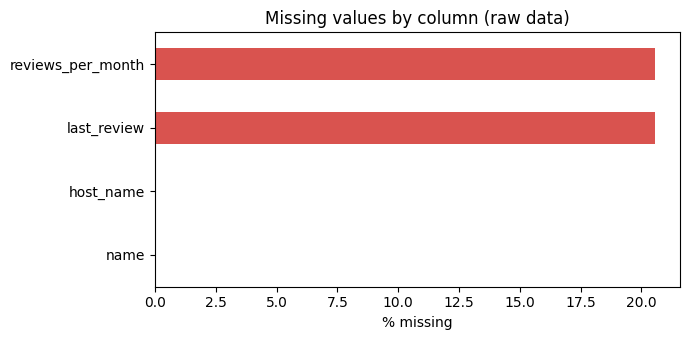

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
missing["missing_pct"].sort_values().plot(kind="barh", ax=ax, color="#d9534f")
ax.set_xlabel("% missing")
ax.set_title("Missing values by column (raw data)")
plt.tight_layout()
plt.show()

#### Why are the review fields missing?

In [8]:
no_reviews = raw["number_of_reviews"] == 0

print("Listings with 0 reviews:", no_reviews.sum())
print("Missing reviews_per_month:", raw["reviews_per_month"].isnull().sum())
print("Missing last_review:", raw["last_review"].isnull().sum())
print("Missing reviews_per_month AND 0 reviews:", (raw["reviews_per_month"].isnull() & no_reviews).sum())
print("Missing last_review AND 0 reviews:", (raw["last_review"].isnull() & no_reviews).sum())

Listings with 0 reviews: 10052
Missing reviews_per_month: 10052
Missing last_review: 10052
Missing reviews_per_month AND 0 reviews: 10052
Missing last_review AND 0 reviews: 10052


### Duplicates

In [9]:
near_dup_cols = ["host_id", "name", "latitude", "longitude", "room_type", "price"]

print("Exact duplicate rows:", raw.duplicated().sum())
print("Repeated listing ids:", raw["id"].duplicated().sum())
print("Near-duplicates (same host, name, location, room type, price):",
      raw.duplicated(subset=near_dup_cols).sum())

Exact duplicate rows: 0
Repeated listing ids: 0
Near-duplicates (same host, name, location, room type, price): 0


### Inconsistent formats

In [10]:
print("last_review is stored as:", raw["last_review"].dtype)
raw["last_review"].head()

last_review is stored as: object


,last_review
0,2018-10-19
1,2019-05-21
2,NaN
3,2019-07-05
4,2018-11-19


#### Extra whitespace in text fields

In [11]:
for col in ["name", "host_name"]:
    s = raw[col].dropna()
    print(f"{col}: leading/trailing spaces = {(s != s.str.strip()).sum()}, "
          f"double spaces = {s.str.contains('  ').sum()}")

name: leading/trailing spaces = 238, double spaces = 1387
host_name: leading/trailing spaces = 0, double spaces = 41


### Category label consistency

In [12]:
for col in ["neighbourhood_group", "neighbourhood", "room_type"]:
    s = raw[col]
    print(f"{col}: unique = {s.nunique()}, "
          f"unique after lower/strip = {s.str.lower().str.strip().nunique()}")

neighbourhood_group: unique = 5, unique after lower/strip = 5
neighbourhood: unique = 221, unique after lower/strip = 221
room_type: unique = 3, unique after lower/strip = 3


### Outliers

#### IQR bounds and outlier counts

In [13]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in ["price", "minimum_nights"]:
    lo, hi = iqr_bounds(raw[col])
    n_out = ((raw[col] < lo) | (raw[col] > hi)).sum()
    print(f"{col}: bounds = ({lo:.0f}, {hi:.0f}), outliers = {n_out} "
          f"({n_out / len(raw) * 100:.1f}%), max = {raw[col].max()}")

print()
print("price == 0:", (raw["price"] == 0).sum())
print("price > 1000:", (raw["price"] > 1000).sum())
print("minimum_nights > 365:", (raw["minimum_nights"] > 365).sum())

price: bounds = (-90, 334), outliers = 2972 (6.1%), max = 10000
minimum_nights: bounds = (-5, 11), outliers = 6607 (13.5%), max = 1250

price == 0: 11
price > 1000: 239
minimum_nights > 365: 14


#### Boxplots (raw data)

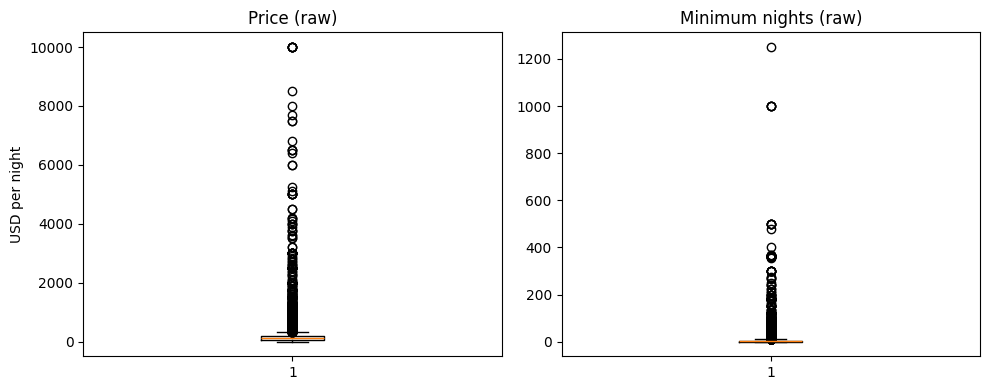

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(raw["price"])
axes[0].set_title("Price (raw)")
axes[0].set_ylabel("USD per night")
axes[1].boxplot(raw["minimum_nights"])
axes[1].set_title("Minimum nights (raw)")
plt.tight_layout()
plt.show()

#### Listings priced at $0

In [15]:
raw.loc[raw["price"] == 0, ["id", "name", "neighbourhood_group", "room_type", "price"]]

,id,name,neighbourhood_group,room_type,price
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Brooklyn,Private room,0
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Bronx,Private room,0
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Brooklyn,Private room,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",Brooklyn,Private room,0
25778,20624541,Modern apartment in the heart of Williamsburg,Brooklyn,Entire home/apt,0
25794,20639628,Spacious comfortable master bedroom with nice ...,Brooklyn,Private room,0
25795,20639792,Contemporary bedroom in brownstone with nice view,Brooklyn,Private room,0
25796,20639914,Cozy yet spacious private brownstone bedroom,Brooklyn,Private room,0
26259,20933849,the best you can find,Manhattan,Entire home/apt,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,Brooklyn,Shared room,0


#### The five most expensive listings

In [16]:
raw.nlargest(5, "price")[["id", "name", "neighbourhood_group", "room_type", "price"]]

,id,name,neighbourhood_group,room_type,price
9151,7003697,Furnished room in Astoria apartment,Queens,Private room,10000
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Entire home/apt,10000
29238,22436899,1-BR Lincoln Center,Manhattan,Entire home/apt,10000
6530,4737930,Spanish Harlem Apt,Manhattan,Entire home/apt,9999
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Private room,9999


### Categorical variables

In [17]:
print(raw["neighbourhood_group"].value_counts(), "\n")
print(raw["room_type"].value_counts(), "\n")
print("neighbourhood has", raw["neighbourhood"].nunique(), "unique values")

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64 

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64 

neighbourhood has 221 unique values


## 5. Cleaning

### Step 1: Cleaning log and duplicate removal

Every step is recorded in a log. No exact, repeated-`id`, or near-duplicate rows exist in this dataset, so nothing is dropped, but the checks stay in so the pipeline is reproducible on other versions of the data.

In [18]:
log = []

def record(step, before, after, note):
    log.append({"step": step, "rows_before": before, "rows_after": after, "note": note})

near_dup_cols = ["host_id", "name", "latitude", "longitude", "room_type", "price"]

n0 = len(df)
df = df.drop_duplicates()                         # exact duplicates
df = df.drop_duplicates(subset=["id"])            # repeated listing ids
df = df.drop_duplicates(subset=near_dup_cols)     # near-duplicates
record("Remove duplicates", n0, len(df), "exact, repeated id, near-duplicate")

print("Rows before:", n0)
print("Rows after: ", len(df))
print("Removed:    ", n0 - len(df))

Rows before: 48895
Rows after:  48895
Removed:     0


### Step 2: Fix formats

Trim and collapse whitespace in text fields and convert `last_review` to a datetime.

In [19]:
# BEFORE
print("--- BEFORE ---")
for col in ["name", "host_name"]:
    s = df[col].dropna()
    print(f"{col}: leading/trailing spaces = {(s != s.str.strip()).sum()}, "
          f"double spaces = {s.str.contains('  ').sum()}")
print("last_review type:", df["last_review"].dtype)

# FIX
for col in ["name", "host_name"]:
    df[col] = df[col].str.strip().str.replace(r"\s+", " ", regex=True)
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")
record("Fix formats", len(df), len(df), "trim whitespace, last_review -> datetime")

# AFTER
print("\n--- AFTER ---")
for col in ["name", "host_name"]:
    s = df[col].dropna()
    print(f"{col}: leading/trailing spaces = {(s != s.str.strip()).sum()}, "
          f"double spaces = {s.str.contains('  ').sum()}")
print("last_review type:", df["last_review"].dtype)

--- BEFORE ---
name: leading/trailing spaces = 238, double spaces = 1387
host_name: leading/trailing spaces = 0, double spaces = 41
last_review type: object

--- AFTER ---
name: leading/trailing spaces = 0, double spaces = 0
host_name: leading/trailing spaces = 0, double spaces = 0
last_review type: datetime64[ns]


### Step 3: Handle missing values

Every missing `reviews_per_month` belongs to a listing with zero reviews, so it is filled with 0 (a true zero, not an unknown). `last_review` stays empty because there is no review date, and a `has_reviews` flag marks those listings. Missing names become `Unknown`.

In [20]:
# names: label as Unknown
df["name"] = df["name"].fillna("Unknown")
df["host_name"] = df["host_name"].fillna("Unknown")

# indicator column, then fill reviews_per_month with 0 only where there are no reviews
df["has_reviews"] = (df["number_of_reviews"] > 0).astype(int)
no_rev = df["number_of_reviews"] == 0
df.loc[no_rev, "reviews_per_month"] = df.loc[no_rev, "reviews_per_month"].fillna(0)

record("Handle missing values", len(df), len(df),
       "Unknown labels; reviews_per_month=0 when no reviews; last_review kept as NaT + has_reviews flag")

print("Missing values after treatment:")
print(df.isnull().sum()[lambda s: s > 0])
print()
df.loc[no_rev, ["number_of_reviews", "reviews_per_month", "last_review", "has_reviews"]].head()

Missing values after treatment:
last_review    10052
dtype: int64



,number_of_reviews,reviews_per_month,last_review,has_reviews
2,0,0.0,NaT,0
19,0,0.0,NaT,0
26,0,0.0,NaT,0
36,0,0.0,NaT,0
38,0,0.0,NaT,0


### Step 4: Treat outliers

#### Remove $0 listings

A price of $0 is not a valid listing price.

In [21]:
n0 = len(df)
df = df[df["price"] > 0].copy()
record("Remove invalid prices", n0, len(df), "price == 0 removed")

print("Rows before:", n0)
print("Rows after: ", len(df))
print("Removed:    ", n0 - len(df))

Rows before: 48895
Rows after:  48884
Removed:     11


#### Cap extreme values and add log price

Price is capped at the 99th percentile and `minimum_nights` at 365 (rows are kept rather than dropped). `log_price` reduces the right skew.

In [22]:
cap_price = df["price"].quantile(0.99)
cap_nights = 365

df["price_capped"] = df["price"].clip(upper=cap_price)
df["minimum_nights_capped"] = df["minimum_nights"].clip(upper=cap_nights)
df["log_price"] = np.log1p(df["price"])

record("Treat outliers", len(df), len(df),
       "winsorize price (99th pct), cap min nights at 365, log price")

print(f"Price capped at the 99th percentile = ${cap_price:.0f}")
print(f"Minimum nights capped at {cap_nights}")
print()
df.nlargest(5, "price")[["price", "price_capped", "minimum_nights", "minimum_nights_capped", "log_price"]]

Price capped at the 99th percentile = $799
Minimum nights capped at 365



,price,price_capped,minimum_nights,minimum_nights_capped,log_price
9151,10000,799,100,100,9.21044
17692,10000,799,5,5,9.21044
29238,10000,799,30,30,9.21044
6530,9999,799,5,5,9.21034
12342,9999,799,99,99,9.21034


#### Before and after charts

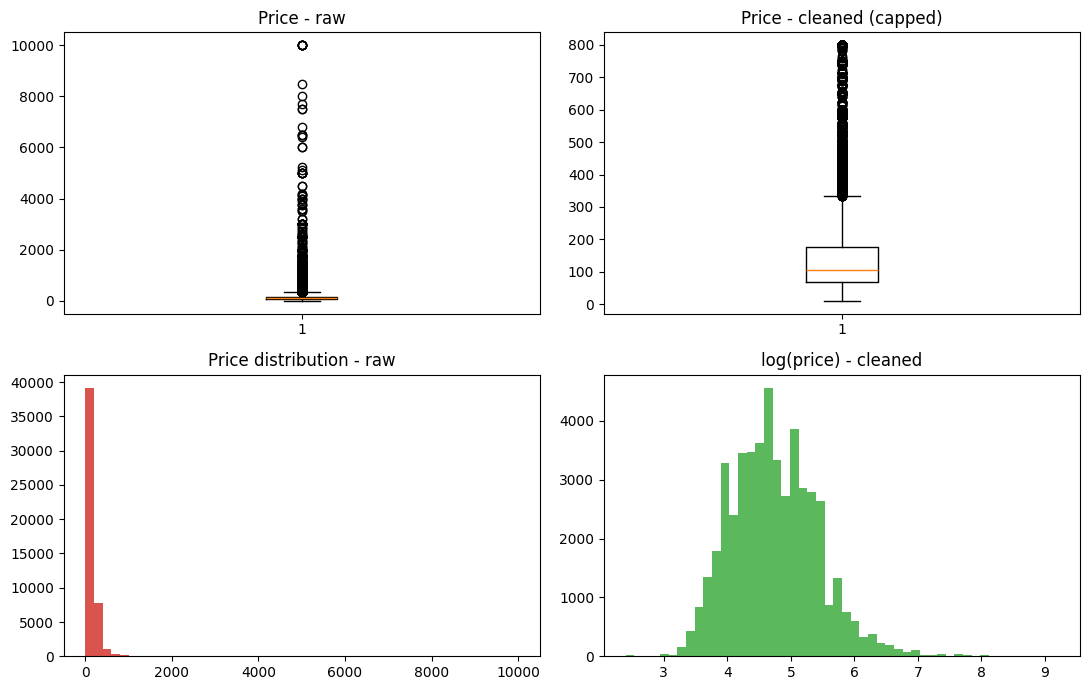

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].boxplot(raw["price"]);          axes[0, 0].set_title("Price - raw")
axes[0, 1].boxplot(df["price_capped"]);    axes[0, 1].set_title("Price - cleaned (capped)")
axes[1, 0].hist(raw["price"], bins=50, color="#d9534f");   axes[1, 0].set_title("Price distribution - raw")
axes[1, 1].hist(df["log_price"], bins=50, color="#5cb85c"); axes[1, 1].set_title("log(price) - cleaned")
plt.tight_layout()
plt.show()

### Step 5: Encode categorical variables

Low-cardinality columns (`room_type`, `neighbourhood_group`) are one-hot encoded. `neighbourhood` has 221 values, so it is frequency-encoded instead.

In [24]:
# low cardinality -> one-hot encoding
df = pd.get_dummies(df, columns=["room_type", "neighbourhood_group"],
                    prefix=["room", "borough"], dtype=int)

# high cardinality (221 values) -> frequency encoding
df["neighbourhood_freq"] = df["neighbourhood"].map(
    df["neighbourhood"].value_counts(normalize=True))

record("Encode categoricals", len(df), len(df),
       "one-hot room_type & borough; frequency-encode neighbourhood")

new_cols = [c for c in df.columns if c.startswith(("room_", "borough_"))] + ["neighbourhood_freq"]
print("New encoded columns:")
for c in new_cols:
    print(" -", c)
print()
df[new_cols].head()

New encoded columns:
 - room_Entire home/apt
 - room_Private room
 - room_Shared room
 - borough_Bronx
 - borough_Brooklyn
 - borough_Manhattan
 - borough_Queens
 - borough_Staten Island
 - neighbourhood_freq



,room_Entire home/apt,room_Private room,room_Shared room,borough_Bronx,borough_Brooklyn,borough_Manhattan,borough_Queens,borough_Staten Island,neighbourhood_freq
0,0,1,0,0,1,0,0,0,0.003580
1,1,0,0,0,0,1,0,0,0.031605
2,0,1,0,0,0,1,0,0,0.054374
3,1,0,0,0,1,0,0,0,0.011701
4,1,0,0,0,0,1,0,0,0.022850


## 6. Results

### Cleaning log

In [25]:
pd.DataFrame(log)

,step,rows_before,rows_after,note
0,Remove duplicates,48895,48895,"exact, repeated id, near-duplicate"
1,Fix formats,48895,48895,"trim whitespace, last_review -> datetime"
2,Handle missing values,48895,48895,Unknown labels; reviews_per_month=0 when no re...
3,Remove invalid prices,48895,48884,price == 0 removed
4,Treat outliers,48884,48884,"winsorize price (99th pct), cap min nights at ..."
5,Encode categoricals,48884,48884,one-hot room_type & borough; frequency-encode ...


### Raw vs cleaned summary

In [26]:
summary = pd.DataFrame({
    "Raw": [len(raw), raw.isnull().sum().sum(), raw.duplicated(subset=near_dup_cols).sum(),
            raw["price"].max(), raw["price"].mean(), raw["price"].std(),
            raw["minimum_nights"].max()],
    "Cleaned": [len(df), df.isnull().sum().sum(), df.duplicated(subset=["id"]).sum(),
                df["price_capped"].max(), df["price_capped"].mean(), df["price_capped"].std(),
                df["minimum_nights_capped"].max()],
}, index=["Rows", "Total missing cells", "Duplicate records", "Max price",
          "Mean price", "Std of price", "Max minimum_nights"]).round(2)
summary

,Raw,Cleaned
Rows,48895.00,48884.00
Total missing cells,20141.00,10051.00
Duplicate records,0.00,0.00
Max price,10000.00,799.00
Mean price,152.72,143.99
Std of price,240.15,121.93
Max minimum_nights,1250.00,365.00


### Average price per borough: raw vs cleaned

               raw_mean_price  clean_mean_price  change_pct
Bronx                   87.50             85.83        -1.9
Brooklyn               124.38            119.42        -4.0
Manhattan              196.88            182.96        -7.1
Queens                  99.52             96.10        -3.4
Staten Island          114.81            101.80       -11.3


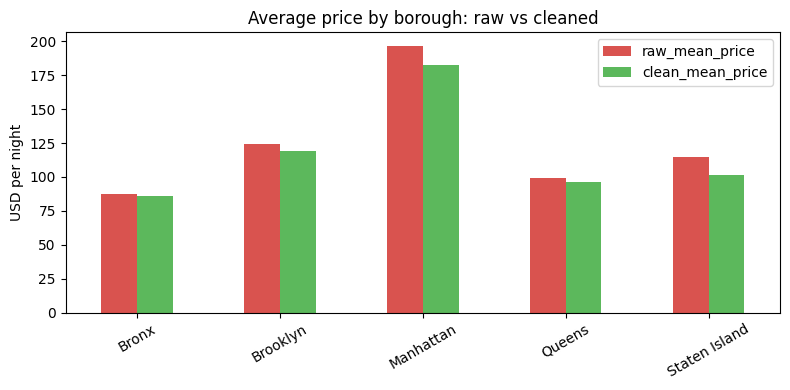

In [27]:
borough_cols = [c for c in df.columns if c.startswith("borough_")]
clean_by_borough = {c.replace("borough_", ""): df.loc[df[c] == 1, "price_capped"].mean()
                    for c in borough_cols}
raw_by_borough = raw.groupby("neighbourhood_group")["price"].mean()

compare = pd.DataFrame({"raw_mean_price": raw_by_borough,
                        "clean_mean_price": pd.Series(clean_by_borough)}).round(2)
compare["change_pct"] = ((compare["clean_mean_price"] / compare["raw_mean_price"] - 1) * 100).round(1)
print(compare)

ax = compare[["raw_mean_price", "clean_mean_price"]].plot(
    kind="bar", figsize=(8, 4), color=["#d9534f", "#5cb85c"])
ax.set_ylabel("USD per night")
ax.set_title("Average price by borough: raw vs cleaned")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 7. Key findings and limitations

**What the cleaning changed**
- **Rows:** 48,895 → 48,884 (the 11 listings priced at $0 were removed).
- **Missing cells:** 20,141 → 10,051. The remaining gaps are all `last_review` for listings that have never been reviewed, flagged by `has_reviews`. The review-field gaps were structural (zero reviews), not random errors.
- **Price:** capped at the 99th percentile ($799); mean $152.72 → $143.99 and standard deviation $240.15 → $121.93. A `log_price` column was added to reduce skew.
- **`minimum_nights`:** maximum 1,250 → 365.
- **By borough:** average price fell everywhere, most in Staten Island (−11.3%) and Manhattan (−7.1%), where extreme listings had the largest influence; Bronx fell least (−1.9%).
- **Duplicates:** none existed, so no rows were dropped at that step.

**Limitations and judgment calls**
- Capping at the 99th percentile keeps every row but changes the top of the price distribution. A different threshold, or removing outliers instead, would give different averages.
- `neighbourhood_freq` encodes how common a neighbourhood is, not how expensive it is.
- The data is a single 2019 snapshot and does not reflect current prices.

**Possible next steps:** exploratory analysis (price by room type and borough, maps), and a baseline model to predict `log_price` from the cleaned features.

## 8. Save the cleaned dataset

In [28]:
# Save next to the raw data when possible; fall back to the current folder
# (e.g. Kaggle's input directory is read-only).
out_dir = os.path.dirname(path)
if not os.access(out_dir or ".", os.W_OK):
    out_dir = "."
out_path = os.path.join(out_dir, "AB_NYC_2019_clean.csv")
df.to_csv(out_path, index=False)
print("Saved to:", out_path)

Saved to: /content/AB_NYC_2019_clean.csv


## 9. About this project

**Author:** Andre Jelani — [GitHub](https://github.com/j3turi) ·
Completed as part of the DSA1101 group project

**Data source:** New York City Airbnb Open Data (Kaggle), 2019.

**Tools:** Python, pandas, NumPy, matplotlib.